In [24]:
import gzip
import ast
from matplotlib import pyplot as plt

In [5]:
file_path = "../data/raw/australian_users_items.json.gz"

with gzip.open(file_path, "rt", encoding="utf-8") as f:
    first_line = f.readline()

print(first_line[:500])


{'user_id': '76561197970982479', 'items_count': 277, 'steam_id': '76561197970982479', 'user_url': 'http://steamcommunity.com/profiles/76561197970982479', 'items': [{'item_id': '10', 'item_name': 'Counter-Strike', 'playtime_forever': 6, 'playtime_2weeks': 0}, {'item_id': '20', 'item_name': 'Team Fortress Classic', 'playtime_forever': 0, 'playtime_2weeks': 0}, {'item_id': '30', 'item_name': 'Day of Defeat', 'playtime_forever': 7, 'playtime_2weeks': 0}, {'item_id': '40', 'item_name': 'Deathmatch Cl


In [6]:
user = ast.literal_eval(first_line)

print(user["items_count"])

277


In [8]:
if user["items"]:
    print(user["items"][0])


{'item_id': '10', 'item_name': 'Counter-Strike', 'playtime_forever': 6, 'playtime_2weeks': 0}


In [9]:
with gzip.open(file_path, "rt", encoding="utf-8") as f:
    for i in range(5):
        user = ast.literal_eval(f.readline())

        print("User:", user["user_id"])
        print("Items count:", user["items_count"])
        print("Actual list length:", len(user["items"]))
        print("-" * 30)

User: 76561197970982479
Items count: 277
Actual list length: 277
------------------------------
User: js41637
Items count: 888
Actual list length: 888
------------------------------
User: evcentric
Items count: 137
Actual list length: 137
------------------------------
User: Riot-Punch
Items count: 328
Actual list length: 328
------------------------------
User: doctr
Items count: 541
Actual list length: 541
------------------------------


In [10]:

import pandas as pd

playtimes = []

with gzip.open(
    "../data/raw/australian_users_items.json.gz",
    "rt",
    encoding="utf-8"
) as f:
    for line in f:
        user = ast.literal_eval(line)

        for item in user["items"]:
            playtimes.append(item["playtime_forever"])

playtime = pd.Series(playtimes)

print(playtime.describe())


count    5.153209e+06
mean     9.914951e+02
std      5.418204e+03
min      0.000000e+00
25%      0.000000e+00
50%      3.400000e+01
75%      3.550000e+02
max      6.427730e+05
dtype: float64


In [33]:
playtime_count = playtime.count()
playtime_zero = playtime[playtime == 0].count()
playtime_under_10h = playtime[(playtime <= 600) & (playtime > 0)].count()
playtime_between_10h_100h = playtime[(playtime > 600) & (playtime <= 6000)].count()
playtime_more_100h = playtime[(playtime > 6000)].count()


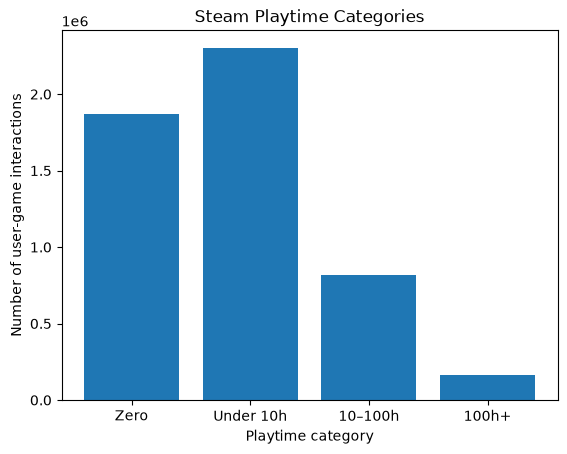

In [34]:
categories = ["Zero", "Under 10h", "10–100h", "100h+"]

counts = [
    playtime_zero,
    playtime_under_10h,
    playtime_between_10h_100h,
    playtime_more_100h
]

plt.bar(categories, counts)
plt.xlabel("Playtime category")
plt.ylabel("Number of user-game interactions")
plt.title("Steam Playtime Categories")
plt.show()

In [35]:
category_total = (
    playtime_zero
    + playtime_under_10h
    + playtime_between_10h_100h
    + playtime_more_100h
)

print("Total interactions:", playtime_count)
print("Categorized interactions:", category_total)

assert category_total == playtime_count

Total interactions: 5153209
Categorized interactions: 5153209


Text(0, 0.5, 'Number of user-game interactions')

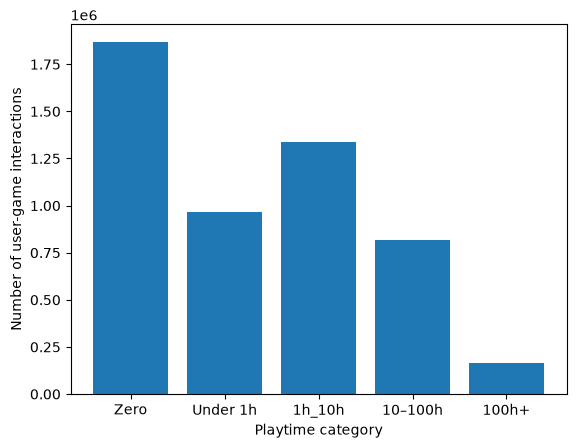

In [38]:
playtime_under_1h = playtime[(playtime > 0) & (playtime <= 60)].count()
playtime_between_1h_10h = playtime[(playtime > 60) & (playtime <= 600)].count()

categories = ["Zero", "Under 1h", "1h_10h", "10–100h", "100h+"]

counts = [
    playtime_zero,
    playtime_under_1h,
    playtime_between_1h_10h,
    playtime_between_10h_100h,
    playtime_more_100h
]

plt.bar(categories, counts)
plt.xlabel("Playtime category")
plt.ylabel("Number of user-game interactions")

In [39]:
playtime.describe()

count    5.153209e+06
mean     9.914951e+02
std      5.418204e+03
min      0.000000e+00
25%      0.000000e+00
50%      3.400000e+01
75%      3.550000e+02
max      6.427730e+05
dtype: float64

In [50]:
zero = playtime_zero/playtime_count * 100
under_1h = playtime_under_1h/playtime_count * 100
more_10h = ((playtime_between_10h_100h +playtime_more_100h)/playtime_count) * 100

In [51]:
print(zero.item())
print(under_1h)
print(more_10h)

36.248539502279066
18.712184970568824
19.093267903552913


In [52]:
playtime.describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.99])

count    5.153209e+06
mean     9.914951e+02
std      5.418204e+03
min      0.000000e+00
25%      0.000000e+00
50%      3.400000e+01
75%      3.550000e+02
90%      1.577000e+03
99%      1.794700e+04
max      6.427730e+05
dtype: float64

In [55]:
import gzip
import ast
import pandas as pd

rows = []

with gzip.open(file_path, "rt", encoding="utf-8") as f:
    for i in range(5):
        user = ast.literal_eval(f.readline())
        user_id = user["user_id"]

        for item in user["items"]:
            game_id = item["item_id"]
            play_time = item["playtime_forever"]
            positive_60m = play_time >= 60

            interaction = {
                "user_id": user_id,
                "game_id": game_id,
                "play_time": play_time,
                "positive_60m": positive_60m
            }

            rows.append(interaction)

df = pd.DataFrame(rows)
df.head(10)

,user_id,game_id,play_time,positive_60m
0,76561197970982479,10,6,False
1,76561197970982479,20,0,False
2,76561197970982479,30,7,False
3,76561197970982479,40,0,False
4,76561197970982479,50,0,False
5,76561197970982479,60,0,False
6,76561197970982479,70,0,False
7,76561197970982479,130,0,False
8,76561197970982479,300,4733,True
9,76561197970982479,240,1853,True


In [56]:
print(df.shape)
print(df.dtypes)
print(df.isna().sum())
print(df.duplicated(subset=["user_id", "game_id"]).sum())

(2171, 4)
user_id           str
game_id           str
play_time       int64
positive_60m     bool
dtype: object
user_id         0
game_id         0
play_time       0
positive_60m    0
dtype: int64
0


In [57]:
assert (df["play_time"] >= 0).all()

assert (
    df["positive_60m"] == (df["play_time"] >= 60)
).all()

In [58]:
from pathlib import Path

batch_size = 100_000
rows = []
batch_number = 0

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

with gzip.open(file_path, "rt", encoding="utf-8") as f:
    for line in f:
        user = ast.literal_eval(line)
        user_id = user["user_id"]

        for item in user["items"]:
            play_time = item["playtime_forever"]

            interaction = {
                "user_id": user_id,
                "game_id": item["item_id"],
                "play_time": play_time,
                "positive_60m": play_time >= 60
            }

            rows.append(interaction)

            if len(rows) >= batch_size:
                df_batch = pd.DataFrame(rows)

                output_path = output_dir / f"interactions_{batch_number:03d}.parquet"
                df_batch.to_parquet(output_path, index=False)

                rows.clear()
                batch_number += 1

    if len(rows) > 0:
        df_batch = pd.DataFrame(rows)

        output_path = output_dir / f"interactions_{batch_number:03d}.parquet"
        df_batch.to_parquet(output_path, index=False)

        batch_number += 1

        print(f"Total batches saved: {batch_number}")

Total batches saved: 52


In [59]:
import pyarrow.parquet as pq

parquet_files = sorted(output_dir.glob("interactions_*.parquet"))

total_rows = 0

for file in parquet_files:
    number_of_rows = pq.ParquetFile(file).metadata.num_rows
    total_rows += number_of_rows

print("Number of files:", len(parquet_files))
print("Total interactions:", total_rows)

assert len(parquet_files) == 52
assert total_rows == 5_153_209

Number of files: 52
Total interactions: 5153209


In [60]:
df_check = pd.read_parquet(parquet_files[0])

print(df_check.dtypes)
print(df_check.isna().sum())

df_check.head()

user_id           str
game_id           str
play_time       int64
positive_60m     bool
dtype: object
user_id         0
game_id         0
play_time       0
positive_60m    0
dtype: int64


,user_id,game_id,play_time,positive_60m
0,76561197970982479,10,6,False
1,76561197970982479,20,0,False
2,76561197970982479,30,7,False
3,76561197970982479,40,0,False
4,76561197970982479,50,0,False
